# Efficiency Matters – Gentle Introduction to Complexity
## Colab Slide Notebook

Based on Chapter 2. 
Computational Thinking for Life Scientists, Chor and Rubenstein, Cambridge University Press



⏩ = optional slide — can be skipped if time is short

## Chapter overview — main points

- Complexity is one of the most fundamental ideas in computer science.
- Algorithms are evaluated mainly by:
  - running time
  - memory usage
- We focus mainly on **time complexity**.
- The goal is intuition, not formal proof-heavy analysis.
- Students should learn to:
  - relate running time to input size
  - estimate actual running time
  - recognize when an algorithm is too slow to be practical


## 2.1 Running Time of Algorithms — main points

- Code quality is not measured only by shortness.
- Shorter code does **not** necessarily mean a better algorithm.
- Efficiency usually concerns two resources:
  - time
  - memory
- One direct way to evaluate efficiency is to **measure actual running time**.
- Python provides `time.perf_counter()` for high-resolution timing.


## Measuring time

In [ ]:
import time
def stopper():
    # function perf_counter() returns the current "processor time", expressed
    # as a floating point number, in seconds
    t0 = time.perf_counter()
    i = 0

    while i<10**7:
        i = i+1

    t1 = time.perf_counter()
    return t1-t0

print(stopper())
print(stopper())
print(stopper())
print(stopper())
print(stopper())

## ⏩ Measuring time

In [ ]:
stopper()

## ⏩ Measuring time

In [ ]:
stopper()

## ⏩ Example outputs — timing experiment

Main points:
- repeated runs give slightly different times
- actual timing depends on the machine and system state
- timing is useful, but it is not the full story


## Exercise 1
Change the loop to execute `10**7` iterations, and run it three times. 
- What is the running time now? 
- How does it compare to the `10**6` iterations?

## Why actual timing is not enough ?

- Actual running time changes from one computer to another.
- Even on the same computer, timing can vary.
- Timing on one particular input tells little about other inputs.
- Therefore computer scientists study the **number of operations as a function of input size**.
- That leads to the idea of **time complexity**.


## 2.2 Linear and Quadratic Time Complexity

- The important question is not only “how long did it run?”
- The deeper question is:
  **How does running time grow when input size grows?**
- A loop over all items in a list gives a **linear** pattern.
- A nested loop over all pairs gives a **quadratic** pattern.
- Growth rate matters more than one isolated timing measurement.


## Linear time complexity


In [ ]:
def linear(L):
    sum = 0
    for i in range(len(L)):
        sum += L [i]

## ⏩ Linear time complexity

In [ ]:
# Testing the function for for lists of 1000, 2000,..., 10000 elements
# Print table with time taken for each list size
# |  Number of elements | Time taken (seconds) |
import time
print("|  Number of elements | Time taken (seconds) |")
for n in range(1000, 10001, 1000):
    L = list(range(n))
    start_time = time.perf_counter()
    linear(L)
    end_time = time.perf_counter()
    print(f"|   {n:17} | {end_time - start_time:20.6f} |")

## Linear time complexity

In [ ]:
# Code that produces a plot of the time taken for each list size
import matplotlib.pyplot as plt
list_sizes = []
times = []
for n in range(1000, 10001, 1000):
    L = list(range(n))
    start_time = time.perf_counter()
    linear(L)
    end_time = time.perf_counter()
    list_sizes.append(n)
    times.append(end_time - start_time)

# Show the plot
plt.plot(list_sizes, times, marker='o')
plt.title('Time taken for linear function')
plt.xlabel('Number of elements')
plt.ylabel('Time taken (seconds)')
plt.grid()
plt.show()

## Linear growth — main points

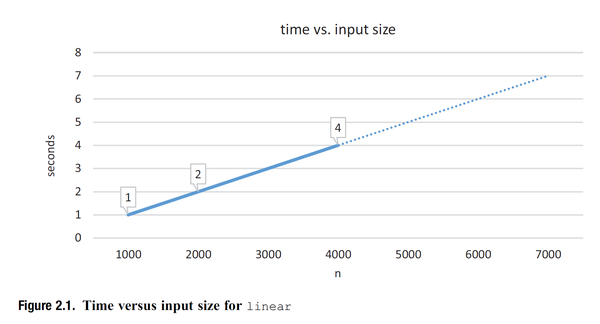

- `linear(L)` prints every element once.
- If the list length doubles, the work roughly doubles.
- This is called **linear growth**.
- Graphically, the time-vs-input-size plot is approximately a straight line.


## `linear_too` - another linear algorithm


In [ ]:
def linear_too(L):
    sum = 0
    for i in range(0,len(L),2): # Loop through the list with a step of 2,
                                # so we only access every other element
        sum += L [i]

# Plot of the time taken for each list size
import matplotlib.pyplot as plt
list_sizes = []
times = []
for n in range(1000, 10001, 1000):
    L = list(range(n))
    start_time = time.perf_counter()
    linear_too(L)
    end_time = time.perf_counter()
    list_sizes.append(n)
    times.append(end_time - start_time)

# Show the plot
plt.plot(list_sizes, times, marker='o')
plt.title('Time taken for linear_too function')
plt.xlabel('Number of elements')
plt.ylabel('Time taken (seconds)')
plt.grid()
plt.show()

## ⏩ `linear_too` — main points

- This version adds only every second element.
- It does less work than `linear`.
- But the **growth class is still linear**.
- Constants matter for actual time, but not for the overall linear trend.



## ⏩ Figure 2.2. Time versus input size for `linear_too`

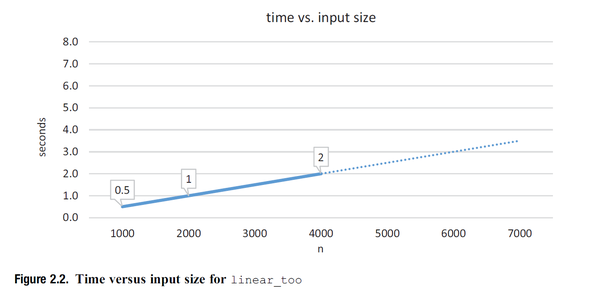

- still a line-like growth
- lower than `linear`
- same asymptotic class: linear

## Mesuring time complexity

* When analyzing an algorithm, the key interest is **how running time grows as the input size increases**.
* **Actual running time is important**, but by itself it is not sufficient for evaluating an algorithm.
* Measured time depends on many **external factors**, such as:

  * computer hardware speed
  * programming language
  * implementation details
  * system load and other environment conditions.
* Therefore, to evaluate **algorithm efficiency rather than machine speed**, we analyze the **growth of running time as a function of input size**.
* Many expressions represent the same **linear growth behavior**, for example:

  * $n$
  * $n/2$
  * $1000n$
  * $\frac{17}{2}n + 32$.
* When plotted as functions of (n), all of these expressions produce **straight lines**, meaning they all represent **linear time complexity**, despite having different constants.
* They do **not** have the same actual running time.
* They do belong to the same **complexity class**.
* Linear time complexity is denoted **$O(n)$**.


## Linear time complexity
### 🤔 What is the complexity of the code?

In [ ]:
n = 1000
count = 0
for i in range(0, n, 2):
    count += 1
print(count)

## ✅ Answer
**$O(n)$** — linear time.
Why: the loop runs n/2 times (500 for n = 1000); a step of 2 halves the work, but constants are dropped: $O(n/2) = O(n)$.

In [ ]:
n = 1000
count = 0
for i in range(0, n, 2):
    count += 1
print(count)

500


## ⏩ Exercise 2 — palindrome

A palindrome is a string that is read the same forward and backward. For example, the strings “ABBA,” “kayak,” and “racecar” are English palindromes. Write a function `is_pal(st)` that takes a string and returns `True` if it is a palindrome, and `False` if it is not. Your function should work in linear time complexity, where $n$ is the number of characters in `st`. Specifically, try to limit yourself to only about $n/2$ loop iterations.


## ⏩ Palindrome solution

In [ ]:
# the function is_palindrome() that checks if a string is a palindrome
def is_pal(string):
    n = len(string)
    for i in range(n // 2): # Loop through the first half of the string
        if string[i] != string[n-1-i]:
            return False
    return True

# Testing the function with some examples
print("racecar", is_pal("racecar")) # True
print("hello", is_pal("hello")) # False
print("AGCTCGA", is_pal("AGCTCGA")) # True

## Quadratic time complexity


In [ ]:
def quadratic(L):
    sum_prod = 0
    for i in range(len(L)):
        for j in range(len(L)):
            sum_prod += L [i] * L [j]

## Quadratic time complexity

In [ ]:
# Plot of the time taken for each list size
import matplotlib.pyplot as plt
list_sizes = []
times = []
for n in range(100, 1201, 100):
    L = list(range(n))
    start_time = time.perf_counter()
    quadratic(L)
    end_time = time.perf_counter()
    list_sizes.append(n)
    times.append(end_time - start_time)
# Show the plot
plt.plot(list_sizes, times, marker='o')
plt.title('Time taken for quadratic function')
plt.xlabel('Number of elements')
plt.ylabel('Time taken (seconds)')
plt.grid()
plt.show()

## Quadratic growth 
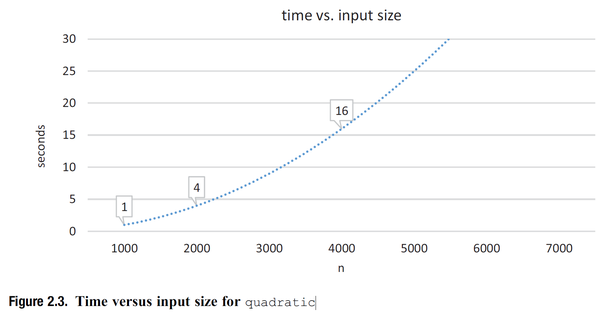

- `quadratic(L)` adds the products of all ordered pairs.
- For length `n`, this gives about `n²` operations.
- If input size doubles, running time grows by about a factor of 4.
- faster upward growth than linear
- shows why nested loops can become expensive quickly
- This is called **quadratic growth**.


## `quadratic_too` - also quadratic time complexity


In [ ]:
def quadratic_too(L):
    sum_prod = 0
    for i in range(len(L)):
        for j in range(i,len(L)): # note the change
            sum_prod += L [i] * L [j]

## ⏩ `quadratic_too` - also quadratic time complexity

In [ ]:
# Plot of the time taken for each list size
import matplotlib.pyplot as plt
list_sizes = []
times = []
for n in range(100, 1201, 100):
    L = list(range(n))
    start_time = time.perf_counter()
    quadratic_too(L)
    end_time = time.perf_counter()
    list_sizes.append(n)
    times.append(end_time - start_time)
# Show the plot
plt.plot(list_sizes, times, marker='o')
plt.title('Time taken for quadratic function')
plt.xlabel('Number of elements')
plt.ylabel('Time taken (seconds)')
plt.grid()
plt.show()

## Quadratic time complexity
### 🤔 What is the complexity of the code?

In [ ]:
n = 4
count = 0
for i in range(n):
    for j in range(i, n):
        count += 1
print(count)

## ✅ Answer
**$O(n^2)$** — quadratic time.
Why: the inner loop runs n + (n−1) + … + 1 = n(n+1)/2 times (10 for n = 4); about half of n², but constants are dropped.

In [ ]:
n = 4
count = 0
for i in range(n):
    for j in range(i, n):
        count += 1
print(count)

10


## ⏩ Table 2.1

**Table 2.1.** This loop iterates only over the pairs `i, j` that appear in the colored cells.  
The orange diagonal includes pairs where `i = j`, and the pink triangle above it is where `i < j`.

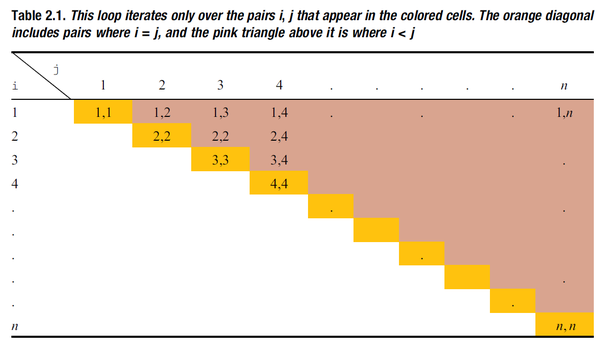


## ⏩ `quadratic_too` — main points

- This version removes about half the pairs.
- It is faster in practice than `quadratic` 
- But its dominant term is still quadratic.
- Sum of arithmetic series $n + (n-1) + (n-2) + ... + 1$ is $\frac{n(n+1)}{2}$, which is $O(n²)$.
- Therefore its asymptotic complexity remains **$O(n²)$**.


## Linear vs quadratic — comparison points

- For small inputs, constants can matter a lot.
- For large inputs, growth rate usually dominates.
- A linear algorithm will eventually beat a quadratic one for large enough input size.
- This is why asymptotic thinking is so important.


## 2.3 The Big-$O$ Notation

- Big-$O$ notation is a compact way to describe complexity classes.
- $O(n)$ means linear time.
- $O(n^2)$ means quadratic time.
- It focuses on the **dominant part** of the running-time expression.
- It is excellent for comparing growth rates on large inputs.


## Big-$O$ notation — limits and interpretation

- Big-$O$ notation hides constants and lower-order terms.
- This makes it powerful but coarse.
- Two algorithms in the same O-class can still differ greatly in actual speed.
- Good practice:
  - analyze asymptotic complexity
  - also measure actual running time


## 2.4 Best-Case, Worst-Case 

- Some algorithms depend not only on input size, but also on the input itself.
- Search is a classic example.
- Best case and worst case can differ significantly.
- Worst-case analysis is the most common in algorithm analysis.


## `search` - searching an element in a list
What is the best case and worst case time complexity of this code (as a function of the length $n$ of the list `L`)?


In [4]:
def search(L, x):
    for item in L:
        if item == x:
            return True
    return False

print(search([1, 2, 3, 4, 5], 1)) # best case
print(search([1, 2, 3, 4, 5], 5)) # worst case

True
True


## `search` - complexity analysis:

- Best case:
  - the element is first
  - only one comparison
  - **$O(1)$**
- Worst case:
  - the element is absent
  - all elements are checked
  - **$O(n)$**
- Average case is often harder to analyze.

> 📌 **Worst-case analysis is the one considered in most cases.**

## Best case and worst case
### 🤔 What is the complexity of `comparisons` in the best case and in the worst case?

In [ ]:
def comparisons(L, x):
    """Return the number of comparisons made by a linear search for x in L."""
    for k in range(len(L)):
        if L[k] == x:
            return k + 1
    return len(L)

L = [4, 8, 15, 16, 23, 42]
print(comparisons(L, 4))
print(comparisons(L, 42))
print(comparisons(L, 7))

## ✅ Answer
Best case **$O(1)$**, worst case **$O(n)$**.
Why: if `x` is the first element the loop stops after 1 comparison; if it is last or absent, all n elements are compared.

In [ ]:
def comparisons(L, x):
    """Return the number of comparisons made by a linear search for x in L."""
    for k in range(len(L)):
        if L[k] == x:
            return k + 1
    return len(L)

L = [4, 8, 15, 16, 23, 42]
print(comparisons(L, 4))
print(comparisons(L, 42))
print(comparisons(L, 7))

1
6
6


## 2.5 Binary Search and Logarithmic Time Complexity 

- Binary search works on a **sorted** list.
- It repeatedly cuts the search interval roughly in half.
- This gives **logarithmic** time complexity.
- Logarithmic algorithms are far more efficient than linear or quadratic ones on large inputs.


##  `binary_search`
- Start in the middle.
- If the middle is too large, search left half.
- If the middle is too small, search right half.
- Each iteration halves the remaining search region.
- Complexity: **$O(\log{n})$**.


In [2]:
def binary_search(L, x):
    '''search for x in the *sorted* list L using binary search algorithm'''
    # left is the index of the first element in the list, right is the index of
    # the last element. Note the assignment of both left and right in the same
    # line
    left, right = 0, len(L)-1

    while left <= right:        # while there are still elements to check
        # mid is the index of the middle element in the list. Note the floor
        # division operator // that rounds down to integer
        mid = (left+right)//2
        # the middle element is the one we are looking for
        if L[mid] == x:
            return True
        # the required element is in the left half of the list
        elif L[mid]> x:
            right = mid-1       # set right to mid-1 to search in the left half
        # the required element is in the right half of the list
        else:
            left = mid+1        # set left to mid+1 to search in the right half

    return False

## `binary_search`

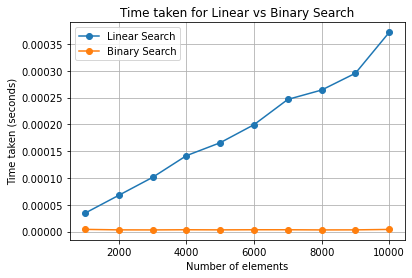

|  Number of elements |   Linear Search (seconds) |   Binary Search (seconds) |
|                1000 |                  0.000034 |                  0.000004 |
|                2000 |                  0.000068 |                  0.000003 |
|                3000 |                  0.000101 |                  0.000003 |
|                4000 |                  0.000142 |                  0.000003 |
|                5000 |                  0.000166 |                  0.000003 |
|                6000 |                  0.000200 |                  0.000003 |
|                7000 |                  0.000247 |                  0.000003 |
|                8000 |                  0.000264 |                  0.000003 |
|                9000 |                  0.000296 |                  0.000003 |
|               10000 |                  0.000372 |                  0.000004 |


In [6]:
# Test binary_search vs. linear search for lists of 1000, 2000,..., 10000
# elements
# and plot the time taken for each list size
import time
import matplotlib.pyplot as plt
list_sizes = []
linear_times = []
binary_times = []
for n in range(1000, 10001, 1000):
    # create a sorted list of n elements [0, 1, 2, ..., n-1]
    L = list(range(n))
    # search for the last element in the list to get the worst case time for
    # linear search
    x = n-1

    start_time = time.perf_counter()
    search(L, x)
    end_time = time.perf_counter()
    linear_times.append(end_time - start_time)

    start_time = time.perf_counter()
    binary_search(L, x)
    end_time = time.perf_counter()
    binary_times.append(end_time - start_time)

    list_sizes.append(n)
# Show the plot
plt.plot(list_sizes, linear_times, marker='o', label='Linear Search')
plt.plot(list_sizes, binary_times, marker='o', label='Binary Search')
plt.title('Time taken for Linear vs Binary Search')
plt.xlabel('Number of elements')
plt.ylabel('Time taken (seconds)')
plt.grid()
# Show the legend to explain which line corresponds to which algorithm
plt.legend()
plt.show()

# Show the table with time taken for each list size
print("|  Number of elements |   Linear Search (seconds) |   Binary Search "
      "(seconds) |")
# zip() function combines three lists into a single list of tuples
for n, linear_time, binary_time in zip(list_sizes, linear_times, binary_times):
    print(f"|   {n:17} | {linear_time:25.6f} | {binary_time:25.6f} |")

## Binary search: halving
### 🤔 What is the complexity of the code?

In [ ]:
n = 1000
steps = 0
while n > 1:
    n = n // 2
    steps += 1
print(steps)

## ✅ Answer
**$O(\log n)$** — logarithmic time.
Why: each step halves n, so 1000 → 500 → … → 1 takes 9 steps ≈ log₂(1000); doubling n adds only one step.

In [ ]:
n = 1000
steps = 0
while n > 1:
    n = n // 2
    steps += 1
print(steps)

9


## 2.6 Exponential Complexity and Tractability — main points

- Polynomial-time algorithms such as:
  - $O(\log n)$
  - $O(n)$
  - $O(n^2)$
  - $O(n^3)$
  are considered **tractable**.
- Exponential-time algorithms such as $O(2^n)$ are usually **intractable**.
- Exponential growth becomes impractical very quickly.


**Table 2.2. Tractable and intractable complexity classes**

Modern Intel i9 CPUs can perform about $10^{10}$ operations per second, so we use that as a benchmark for what can be done in one second.

| Tractability | Complexity class | Maximal $n$ for which running time $\le$ 1 sec |
|---|---|---|
| Tractable | $\log_2 n$ | $n = 2^{10^{10}} = 2^{10{,}000{,}000{,}000}$ |
| Tractable | $n$ | $n = 10^{10} = 10{,}000{,}000{,}000$ |
| Tractable | $n^2$ | $n = \sqrt{10^{10}} = 10^5 = 100{,}000$ |
| Intractable | $2^n$ | $n = \log_2 10^{10} \approx 33$ |


## Exponential complexity

* Even a very fast computer cannot handle large `n` when the complexity is exponential.
* Example: printing all genomic sequences of length `n`.
    * There are `4ⁿ` such sequences.
    * Therefore the task is inherently exponential in output size.


## Exercise 5
Suppose your computer can write $10^{10}$ characters per second to a file. How much
time will it take for an algorithm to print all genomic sequences of length $n = 30$ ?
Ignore the time it takes for that algorithm to compute those sequences (move from
one to the next).

## Solution to Exercise 5

In [7]:
n = 30
num_sequences = 4 ** n          # number of sequences to print
num_chars = n * num_sequences   # each sequence has n characters
chars_per_sec = 10 ** 10        # writing speed

seconds = num_chars / chars_per_sec
minutes = seconds / 60          # 60 seconds in a minute
hours = minutes / 60            # 60 minutes in an hour
days = hours / 24               # 24 hours in a day
years = days / 365              # 365 days in a year

print(f"Time to print all sequences of length {n}:")
print(f"{seconds:,.0f} seconds")
print(f"{minutes:,.0f} minutes")
print(f"{hours:,.0f} hours")
print(f"{days:,.0f} days")
print(f"{years:.2f} years")

Time to print all sequences of length 30:
3,458,764,514 seconds
57,646,075 minutes
960,768 hours
40,032 days
109.68 years


## Exponential growth
### 🤔 What is the complexity of the code?

In [ ]:
n = 10
count = 0
# one iteration for every subset of n items
for subset in range(2 ** n):
    count += 1
print(count)

## ✅ Answer
**$O(2^n)$** — exponential time.
Why: the loop runs 2ⁿ times (1024 for n = 10); adding just 10 to n multiplies the work by about 1000 — intractable for large n.

In [ ]:
n = 10
count = 0
# one iteration for every subset of n items
for subset in range(2 ** n):
    count += 1
print(count)

1024


## 2.7 Useful Tips 

- Built-in functions are useful, but not “free”.
- `min`, `sum`, reversing a list:
  often linear in input size.
- `sorted` is typically $O(n \log{ n})$.
- Slicing a string or list copies data:
  slicing length `m` costs **$O(m)$**.


## Exercise 6 — slicing cost

What is the time complexity of the following code, as a function of `n` (where `st` is
a string)?



In [ ]:
def func(st):
    n = len(st)
    for i in range(n+1):
        print(st [0:i])

## Solution to Exercise 6
Each iteration of the loop creates the slice `st[0:i]` of length `i`, which takes $O(i)$ time.

The total time is the sum of the times for each iteration:

$0 + 1 + 2 + ... + n = \frac{n(n+1)}{2} = O(n^2)$

📌 **Note:**
- slicing is not constant time
- the total work is more than just the loop count

## Slicing is not free
### 🤔 What is the complexity of the code?

In [ ]:
st = "ACGT"
total = 0
for i in range(len(st) + 1):
    total += len(st[0:i])     # characters copied by this slice
print(total)

## ✅ Answer
**$O(n^2)$** — quadratic time.
Why: the loop runs n + 1 times, but slice `st[0:i]` copies i characters: 0 + 1 + … + n = n(n+1)/2 (10 for n = 4).

In [ ]:
st = "ACGT"
total = 0
for i in range(len(st) + 1):
    total += len(st[0:i])     # characters copied by this slice
print(total)

10


## ⏩ multiple inputs: `concat` 


In [ ]:
def concat(st1, st2):
    st3 = st1+st2 # creating new string requires to copy the characters
    # of st1 and st2 to the new string st3,
    # so the time taken is proportional to the length of st1 and st2

    return st3

## ⏩ Multiple inputs 

- Some algorithms depend on more than one input size.
- For `concat(st1, st2)`, if lengths are $n_1$ and $n_2$, then:
  - complexity is $O(n_1 + n_2)$


## ⏩ Biological context 

- In computational biology, inputs can be extremely large:
  - genomes
  - proteomes
  - large sequence collections
- In such settings, even quadratic algorithms can be too slow.
- This motivates searching for linear or near-linear methods whenever possible.


## ⏩ Trust but check 
- An `O(n)` algorithm can still be slower than an `O(n²)` algorithm for small inputs.
- Constants hidden in O notation may dominate at small scales.
- Therefore:
  - theory gives growth behavior
  - timing experiments give practical behavior
- Both are useful.


## Reflection — summary points

- Complexity helps us predict whether an algorithm will scale.
- Time and memory are both important resources.
- Sometimes there is a tradeoff:
  - use more memory to save time
- An inefficient algorithm may be practically useless if it:
  - runs for too long
  - or causes memory overflow


## ⏩ Challenge Yourself — repeating k-mer problem

Main idea:
- Given a string `st` and an integer `k`,
  determine whether a k-mer repeats.
- The chapter begins with a naïve solution
  and later points to a more efficient hashing-based solution.


## ⏩ `repeating_substring_naive1`
What is the time complexity of this code, as a function of `n` (the length of `st`) and `k`?

In [ ]:
def repeating_substring_naive1(st, k):

    n = len(st)

    for i in range(n-k+1):

        for j in range(i+1, n-k+1):

            if st [i:i+k] == st [j:j+k]:

                return st [i:i+k]

    return None

## ⏩ Solution to `repeating_substring_naive1`
For each value of `i` from `0` to `n-k`, 
the inner loop repeats for each value of `j` from `i+1` to `n-k`.
Thus the total number of times `st[i:i+k] == st[j:j+k]` is evaluated is:
$$ (n-k) + (n-k-1) + (n-k-2) + ... + 1 = \frac{(n-k)(n-k+1)}{2} = O(n^2) $$

The comparison `st[i:i+k] == st[j:j+k]` takes `O(k)` time, since it compares two substrings of length `k`.

Therefore, the overall time complexity of `repeating_substring_naive1` is:
$$O(n^2  k)$$



## ⏩ `repeating_substring_wrong`
- Why is this code wrong?
- How would you fix it?


In [ ]:
def repeating_substring_wrong(st, k):

    for i in range(len(st)-k+1):

        if st[i:i+k] in st:

            return st[i:i+k]

    return None

## ⏩ Solution to `repeating_substring_wrong`
The code searches for st[i:i+k] in the whole string `st`, which will always find the substring at index `i` itself, leading to a false positive.

🪛 Fix:
```python
def repeating_substring_wrong(st, k):
    for i in range(len(st) - k + 1):
        if st[i:i+k] in st[i+1:]: # note the slicing to avoid self-match
            return True
    return False
```


## ⏩ `repeating_substring_naive2`
 - Use `count` method to check if a k-mer appears more than once.
 - Complete the following code skeleton to implement this idea.


In [ ]:
def repeating_substring_naive2(st, k):

    for i in range(len(st)-k+1):

        if _______________________:

            return st [i:i+k]

    return None

## ⏩ Solution to `repeating_substring_naive2`
```python
def repeating_substring_naive2(st, k):

    for i in range(len(st)-k+1):

        if st.count(st[i:i+k]) > 1: # use count method to check for repeats

            return st [i:i+k]

    return None

## ⏩ Challenge problem — main points

- We started with a simple but possibly slow solution.
- Analyze:
  - best case
  - worst case
  - effect of `k`
- Identify incorrect “shortcut” ideas.
- Compare naïve and improved approaches.
- Prepare students for the next chapter:
  **hashing improves performance dramatically**.


## Summary of the chapter’s main points:

1. Introduce timing with `stopper`
2. Compare linear and quadratic growth
3. Introduce O notation
4. Show best-case / worst-case
5. Demonstrate binary search
6. Discuss tractability
7. Conclude with practical tips and the repeating k-mer challenge
